# ExpTM lattice gas — reviewed reproduction record

**Review mode is the default. No new training or sampling is enabled.**
Use the ExpTM `.venv` kernel. The notebook retains the uploaded execution outputs;
this review did not rerun PyTorch experiments. Open the notebook to view those outputs.
Running a skipped cell replaces its old output with a skip message; the summary below
remains available. Save the original notebook separately if you want an additional local snapshot.

The first setup cell has three independent switches:
- `RUN_FROM_SCRATCH`: rerun the 10,000-sample training and its evaluation.
- `RUN_CHECKPOINT_COMPARISON`: resample the two saved 10,000-sample checkpoints.
- `RUN_MATCHED_SIZE_WORKFLOW`: rerun the entire appended 2,000-sample workflow,
  including three training seeds, their evaluation, the public checkpoint and the T-control check.

All three default to `False`. Previously, the appended training cells ignored
`RUN_FROM_SCRATCH=False`; that execution-control issue is now fixed.
For an intentional new experiment, enable the appropriate switch and restart before running in order.
The saved-sample diagnostic near the end is read-only and uses recorded paths.

## Recorded results — transcribed from the uploaded outputs

All entries below use 64 samples per control, batch size 16, sampling seed 2026103101
reset separately at each control, `eta=gamma=1`, and coordinate-channel decoding at zero.

| Model / dataset | T control | Density at p=-1 | Density at p=0 | Density at p=+1 |
|---|---:|---:|---:|---:|
| Full input data | — | 0.0481045 | N/A | 0.9515275 |
| Fixed 2,000-sample subset | — | 0.0480575 | N/A | 0.9516400 |
| 10,000 samples, seed 42, saved epoch 1 | 5 | 0.0000391 | 0.9290234 | 0.9999609 |
| 2,000 samples, seed 42, saved epoch 1 | 5 | 0.2581641 | 0.4983984 | 0.7876953 |
| 2,000 samples, seed 43, saved epoch 1 | 5 | 0.1442969 | 0.5162109 | 0.8551172 |
| 2,000 samples, seed 44, saved epoch 1 | 5 | 0.3535937 | 0.5302344 | 0.7050781 |
| Public checkpoint | 5 | 0.3031250 | 0.4993359 | 0.7245313 |
| Public checkpoint | 1 | 0.2480469 | 0.4844141 | 0.6919531 |

The fixed subset had 1,000 samples per endpoint. Each subset model received 64 optimizer
updates over two epochs. The 10,000-sample run received 314 updates. Dataset size and
update count changed together, so their separate causal effects are not identified.
Training seeds also affect Loader dequantization, not only network initialization.
Sampling SEM is uncertainty for a fixed model, not uncertainty across training seeds.

The public model has the same broad three-point density trend as the subset models,
but the results do not establish numerical equivalence or reproduce the input endpoint
densities. Changing its sampling temperature control from 5 to 1 does not resolve this.
No midpoint reference data were supplied; 0.5 is not treated as a validated target here.

## Source and pipeline review

The reviewed notebook consistently constructs channels as `[coordinate, T control, p control]`.
The temporary chemical-potential labels in channel 1 are overwritten by T control 5;
`chemicalP_conversion` is defined but is not used by the active experiments.
The final density is `(samples[:, 0] >= 0).mean(axis=(1, 2))`, equivalent to the
archived author's `round_lattice` for finite arrays. Neither a control channel nor the
signed-coordinate mean is used as the density.

In the previously uploaded core source (byte-identical to the inspected repository archive),
Loader adds Gaussian dequantization noise with scale 0.01 and computes a NormalTransform,
but `__getitem__` returns the unstandardized, dequantized tensor. The active steered sampler
returns coordinates directly and does not use a Loader inverse transform. There is therefore
no evidence in this path for adding a missing inverse-normalization step.
The prior uses mean p and variance T for the coordinate channel. The public checkpoint is
hash-checked and loaded into a separate backbone; no optimizer updates occur during evaluation.

These are source-path findings, not proof of the original public checkpoint's training recipe.
Its original preprocessing, data subset and physical-parameter mapping remain unrecovered.
The T=1 and T=5 code variants do not by themselves define a conversion to physical temperature.
The local source fingerprint diagnostic below checks the current files, not historical files
that may have existed when earlier results were generated.

The next diagnostic reads existing continuous sample arrays before thresholding. It does not
change a threshold, retrain, or resample. It reports whether samples remain far from the binary
input support; it cannot by itself establish the cause of any discrepancy.


In [1]:
import sys
import json
import hashlib
import time
from datetime import datetime
from pathlib import Path
import numpy as np
import torch

ROOT = Path(r"C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1")
SOURCE_DIR = ROOT / "author_source" / "GC_Lattice_gas" / "expTM_data_genenration"
DATA_DIR = ROOT / "author_source" / "GC_Lattice_gas" / "data"
RUN_DIR = ROOT / "outputs" / "from_scratch_20261031_233453_878025"
MODEL_DIR = RUN_DIR / "models"
PREVIOUS_EVAL_DIR = RUN_DIR / "density_check_20261031_234424_647084"

RUN_FROM_SCRATCH = False
RUN_CHECKPOINT_COMPARISON = False
RUN_MATCHED_SIZE_WORKFLOW = False

expected_python = ROOT / ".venv" / "Scripts" / "python.exe"
assert Path(sys.executable).resolve() == expected_python.resolve(), "Select the ExpTM .venv kernel."
assert (SOURCE_DIR / "tm" / "core" / "diffusion_model.py").is_file()
for name in ["LowMuT7.npy", "HighMuT7.npy"]:
    assert (DATA_DIR / name).is_file(), f"Missing data: {name}"
if not RUN_FROM_SCRATCH:
    for epoch in [0, 1]:
        assert (MODEL_DIR / f"model_{epoch}.pt").is_file(), f"Missing checkpoint: epoch {epoch}"
    assert (PREVIOUS_EVAL_DIR / "results.json").is_file(), "Check PREVIOUS_EVAL_DIR."
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Existing run:", RUN_DIR)
print("Retraining enabled:", RUN_FROM_SCRATCH)
print("Matched-size training and sampling enabled:", RUN_MATCHED_SIZE_WORKFLOW)


Python: c:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\.venv\Scripts\python.exe
PyTorch: 2.5.1+cpu
Existing run: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\from_scratch_20261031_233453_878025
Retraining enabled: False


## 1. Imports and the same data preparation

In [2]:
import sys
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

# Use this project's author source.
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from tm.core.loader import Loader
from tm.core.prior import GlobalEquilibriumHarmonicPrior
from tm.core.backbone import ConvBackbone
from tm.core.diffusion_model import DiffusionTrainer, SteeredDiffusionSampler
from tm.core.diffusion_process import VPDiffusion
from tm.architectures.unet_2d_mid_attn import Unet2D

# Our reproducibility setting; the author's seed is not recorded.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)

import tm.core.diffusion_model as diffusion_module

loaded_source = Path(diffusion_module.__file__).resolve()
expected_source = (
    SOURCE_DIR / "tm" / "core" / "diffusion_model.py"
).resolve()

print("Loaded source:", loaded_source)
assert loaded_source == expected_source, (
    "Wrong tm package loaded. Restart the kernel and run from the top."
)
print("Imports passed.")
print("Seed:", SEED)

Loaded source: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\author_source\GC_Lattice_gas\expTM_data_genenration\tm\core\diffusion_model.py
Imports passed.
Seed: 42


In [3]:
# Load all available samples using explicit paths.
low_T_data = np.load(DATA_DIR / "LowMuT7.npy", allow_pickle=False)
high_T_data = np.load(DATA_DIR / "HighMuT7.npy", allow_pickle=False)

LowT_chem = low_T_data
HighT_chem = high_T_data

assert low_T_data.shape[1:] == (2, 20, 20)
assert high_T_data.shape[1:] == (2, 20, 20)
assert len(low_T_data) == len(high_T_data)
assert np.isfinite(low_T_data).all()
assert np.isfinite(high_T_data).all()

chemical_potential = [-4, 4]

def rescale_training_data(low_T_data, high_T_data):
    low = low_T_data.copy()
    high = high_T_data.copy()
    low[:, 1, :, :] = -4
    high[:, 1, :, :] = 4
    return np.concatenate((low, high), axis=0)

def chemicalP_conversion(chemical_potential, mu):
    low, high = min(chemical_potential), max(chemical_potential)
    return 2 * (mu - low) / (high - low) - 1

for name, data in [("LowMuT7", low_T_data), ("HighMuT7", high_T_data)]:
    density = (data[:, 0] >= 0).mean(axis=(1, 2))
    print(f"{name}: shape={data.shape}, mean density={density.mean():.7f}")

print("Total training samples:", len(low_T_data) + len(high_T_data))

LowMuT7: shape=(5000, 2, 20, 20), mean density=0.0481045
HighMuT7: shape=(5000, 2, 20, 20), mean density=0.9515275
Total training samples: 10000


In [4]:
# Rescale and concatenate the data
training_rescaled = rescale_training_data(low_T_data, high_T_data)

# Add a temperature channel with a value of 1
temperature_channel = np.ones((training_rescaled.shape[0], 1, training_rescaled.shape[2], training_rescaled.shape[3]))
expanded_training_data = np.concatenate((training_rescaled, temperature_channel), axis=1)

print(expanded_training_data.shape)  # Expected with the available files: (10000, 3, 20, 20)

(10000, 3, 20, 20)


In [5]:
# Initialize pressure values
pressure = np.array([-1.0, 1.0])
pressure_list = np.ones(HighT_chem.shape[0]*2)
temperature_list = 1 * np.ones(HighT_chem.shape[0]*2)

for i in range(2):
    pressure_list[HighT_chem.shape[0] * i:HighT_chem.shape[0] * (i + 1)] = pressure[i]

# Expand the data to include channels for temperature and pressure
expanded_data_final = np.zeros((expanded_training_data.shape[0], 3, expanded_training_data.shape[2], expanded_training_data.shape[3]))

# Copy the original expanded data
expanded_data_final[:, :3, :, :] = expanded_training_data

# Set channel index 1 to temperature control 5
expanded_data_final[:, 1, :, :] = 5

# Set channel index 2 to pressure control
expanded_data_final[:, 2, :, :] = pressure_list[:, np.newaxis, np.newaxis]


In [6]:
# Create trajectory dictionary
trajectoryP = {'coordinate': [], 'state_variables': [], 'state_variables_P': []}
trajectoryP['coordinate'] = expanded_data_final[:, :3, :, :]
trajectoryP['state_variables_P'] = pressure_list
trajectoryP['state_variables'] = temperature_list*5

print(expanded_data_final.shape)  # Expected with the available files: (10000, 3, 20, 20)

(10000, 3, 20, 20)


In [7]:
trajectoryP['state_variables']

array([5., 5., 5., ..., 5., 5., 5.], shape=(10000,))

In [8]:
train_loader = Loader(data=trajectoryP['coordinate'], pressures =trajectoryP['state_variables_P'][:,None] , temperatures=trajectoryP['state_variables'][:,None],control_dims=(1,3))#, **TMLoader_kwargs)
prior = GlobalEquilibriumHarmonicPrior(shape=train_loader.data.shape, channels_info={"coordinate": [0], "fluctuation": [1], "mean": [2]})
model = Unet2D(dim=32, dim_mults=(1,2,4), resnet_block_groups=8, channels=3)

In [9]:
backbone = ConvBackbone(model=model,
                        data_shape=train_loader.data_dim,target_shape=32,num_dims=4,lr=1e-3,eval_mode="train",self_condition=True)

diffusion = VPDiffusion(num_diffusion_timesteps=100)


## 2. Training record — skipped by default

The output below was saved in the uploaded notebook. `RUN_FROM_SCRATCH=False`
prevents this cell from training again. For a deliberate new run, change that flag
and restart the kernel before Run All. The original cell creates a new output directory.

In [10]:
if RUN_FROM_SCRATCH:
    from datetime import datetime
    import json
    import time
    import hashlib

    # Ensure this is a fresh model, not continued training.
    assert len(backbone.optim.state_dict()["state"]) == 0, (
        "Optimizer already contains training history. "
        "Recreate the model and backbone before training from scratch."
    )

    RUN_DIR = ROOT / "outputs" / (
        "from_scratch_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )
    MODEL_DIR = RUN_DIR / "models"
    MODEL_DIR.mkdir(parents=True, exist_ok=False)

    config = {
        "seed": SEED,
        "samples": len(train_loader.data),
        "epochs": 2,
        "batch_size": 64,
        "loss_type": "smooth_l1",
        "temperature_control": 5,
        "pressure_controls": [-1, 1],
        "diffusion_steps": 100,
        "torch_version": str(torch.__version__),
        "python_executable": sys.executable,
        "data_sha256": {
            name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
            for name in ["LowMuT7.npy", "HighMuT7.npy"]
        },
    }
    (RUN_DIR / "config.json").write_text(
        json.dumps(config, indent=2), encoding="utf-8"
    )
    torch.save(torch.get_rng_state(), RUN_DIR / "before_training_rng.pt")

    trainer = DiffusionTrainer(
        diffusion,
        backbone,
        train_loader,
        prior,
        model_dir=str(MODEL_DIR),
        pred_type="noise",
    )

    print("Output directory:", RUN_DIR)
    print("Starting training: 2 epochs, batch size 64")
    start = time.monotonic()

    trainer.train(2, loss_type="smooth_l1", batch_size=64)

    elapsed = time.monotonic() - start
    checkpoints = sorted(MODEL_DIR.glob("*.pt"))

    (RUN_DIR / "training_summary.json").write_text(
        json.dumps({
            "elapsed_seconds": elapsed,
            "checkpoints": [str(path) for path in checkpoints],
        }, indent=2),
        encoding="utf-8",
    )

    print(f"Training finished in {elapsed:.1f} seconds.")
    print("Saved checkpoints:")
    for path in checkpoints:
        print(path)

## 3. Recorded epoch 1 evaluation
Default: read the existing results and samples. A deliberate new training run also generates a new evaluation.

In [11]:
if RUN_FROM_SCRATCH:
    # Evaluate the model just trained in this notebook.
    sampler = SteeredDiffusionSampler(
        diffusion, backbone, train_loader, prior, pred_type="noise"
    )

    EVAL_DIR = RUN_DIR / (
        "density_check_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )
    EVAL_DIR.mkdir(parents=True, exist_ok=False)

    SAMPLING_SEED = 2026103101
    N_SAMPLES = 64
    BATCH_SIZE = 16

    reference_means = {
        -1: float((low_T_data[:, 0] >= 0).mean()),
        1: float((high_T_data[:, 0] >= 0).mean()),
    }

    results = []
    for p in [-1, 0, 1]:
        # Use the same sampling seed at each control value.
        random.seed(SAMPLING_SEED)
        np.random.seed(SAMPLING_SEED)
        torch.manual_seed(SAMPLING_SEED)

        print(f"\nSampling: T=5, pressure={p}", flush=True)
        parts = []

        for i in range(N_SAMPLES // BATCH_SIZE):
            generated = sampler.sample_loop(
                num_samples=BATCH_SIZE,
                batch_size=BATCH_SIZE,
                temperature=5,
                pressure=p,
                eta=1,
                gamma=1,
            )
            a = generated.detach().cpu().numpy()
            assert a.shape == (BATCH_SIZE, 3, 20, 20)
            assert np.isfinite(a).all()
            parts.append(a)
            print(f"Completed {(i + 1) * BATCH_SIZE}/{N_SAMPLES}",
                  flush=True)

        samples_array = np.concatenate(parts, axis=0)
        np.save(EVAL_DIR / f"samples_pressure_{p}.npy", samples_array)

        # Author's decoding rule: negative -> empty; otherwise occupied.
        densities = (samples_array[:, 0] >= 0).mean(axis=(1, 2))
        reference = reference_means.get(p)

        row = {
            "pressure_control": p,
            "temperature_control": 5,
            "sampling_seed": SAMPLING_SEED,
            "samples": len(densities),
            "density_mean": float(densities.mean()),
            "density_sd": float(densities.std(ddof=1)),
            "density_sem": float(
                densities.std(ddof=1) / np.sqrt(len(densities))
            ),
            "reference_data_mean": reference,
            "difference_from_reference": (
                float(densities.mean() - reference)
                if reference is not None else None
            ),
        }
        results.append(row)
        (EVAL_DIR / "results.json").write_text(
            json.dumps(results, indent=2), encoding="utf-8"
        )
        print(json.dumps(row, indent=2))

    print("\nResults saved to:", EVAL_DIR)
else:
    EVAL_DIR = PREVIOUS_EVAL_DIR
    print("Reading recorded evaluation:", EVAL_DIR)

Reading recorded evaluation: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\from_scratch_20261031_233453_878025\density_check_20261031_234424_647084


p=-1 | generated=0.0000391 +/- 0.0000391 SEM | data=0.0481045
p=+0 | generated=0.9290234 +/- 0.0061423 SEM | data=N/A
p=+1 | generated=0.9999609 +/- 0.0000391 SEM | data=0.9515275
p=-1: density range=[0.0000, 0.0025], empty=63/64, full=0/64
p=+0: density range=[0.7725, 0.9975], empty=0/64, full=0/64
p=+1: density range=[0.9975, 1.0000], empty=0/64, full=63/64


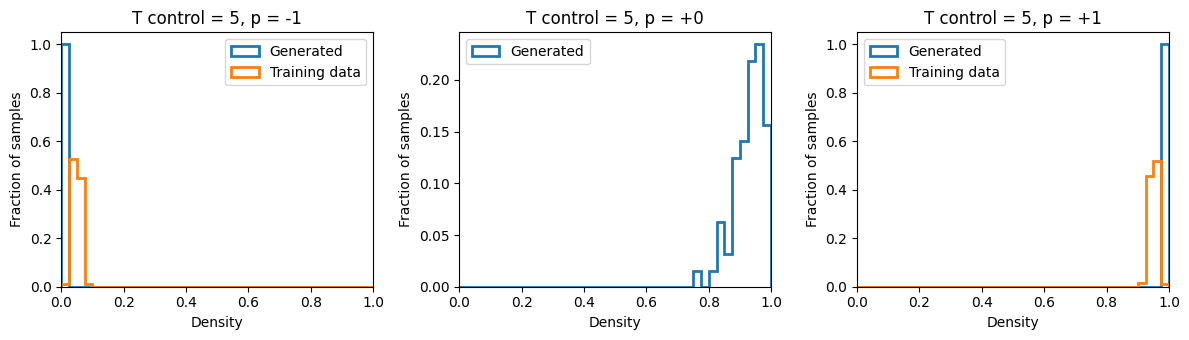

In [12]:
saved_results = json.loads(
    (EVAL_DIR / "results.json").read_text(encoding="utf-8")
)

for row in saved_results:
    ref = row["reference_data_mean"]
    ref_text = "N/A" if ref is None else f"{ref:.7f}"
    print(
        f"p={row['pressure_control']:+d} | "
        f"generated={row['density_mean']:.7f} "
        f"+/- {row['density_sem']:.7f} SEM | "
        f"data={ref_text}"
    )

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
bins = np.linspace(0, 1, 41)

for ax, p in zip(axes, [-1, 0, 1]):
    a = np.load(EVAL_DIR / f"samples_pressure_{p}.npy")
    occupied = a[:, 0] >= 0
    rho = occupied.mean(axis=(1, 2))

    ax.hist(rho, bins=bins, weights=np.ones(len(rho)) / len(rho),
            histtype="step", linewidth=2, label="Generated")

    if p != 0:
        data = low_T_data if p == -1 else high_T_data
        ref_rho = (data[:, 0] >= 0).mean(axis=(1, 2))
        ax.hist(
            ref_rho, bins=bins,
            weights=np.ones(len(ref_rho)) / len(ref_rho),
            histtype="step", linewidth=2, label="Training data"
        )

    print(
        f"p={p:+d}: density range=[{rho.min():.4f}, {rho.max():.4f}], "
        f"empty={np.count_nonzero(rho == 0)}/{len(rho)}, "
        f"full={np.count_nonzero(rho == 1)}/{len(rho)}"
    )
    ax.set(title=f"T control = 5, p = {p:+d}",
           xlabel="Density", ylabel="Fraction of samples", xlim=(0, 1))
    ax.legend()

fig.tight_layout()
if RUN_FROM_SCRATCH:
    fig.savefig(EVAL_DIR / "density_distributions.png", dpi=180)
plt.show()

## 4. New comparison: saved epoch 0 versus epoch 1

Both checkpoints use one shared Loader and the same architecture, `eval_mode="train"`,
T control 5, pressure controls −1/0/+1, eta=gamma=1, and sign-at-zero decoding.
For each checkpoint/control pair, reset the sampling seed to 2026103101 and use four batches of 16.
Each checkpoint is loaded into a separate backbone; no optimizer steps are taken.
`model_0.pt` means the checkpoint after the first epoch; `model_1.pt` means after the second.

This tests whether the density behavior changes between these two saved states.
It does not identify a unique cause or quantify variability across training seeds.
SEM bars describe sampling uncertainty for each fixed checkpoint only.
Hashes below identify the files used now; no historical source hash was recorded in the uploaded training cell.

In [13]:
def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def density_summary(samples, reference):
    rho = (samples[:, 0] >= 0).mean(axis=(1, 2))
    return {
        "samples": len(rho),
        "density_mean": float(rho.mean()),
        "density_sd": float(rho.std(ddof=1)),
        "density_sem": float(rho.std(ddof=1) / np.sqrt(len(rho))),
        "density_min": float(rho.min()),
        "density_max": float(rho.max()),
        "empty_count": int(np.count_nonzero(rho == 0)),
        "full_count": int(np.count_nonzero(rho == 1)),
        "reference_data_mean": reference,
        "difference_from_reference": float(rho.mean() - reference) if reference is not None else None,
    }

def compare_saved_checkpoints():
    # Use the CPU environment of the recorded run.
    assert not torch.cuda.is_available(), "This comparison is configured for the recorded CPU environment."
    n_samples, batch_size, sampling_seed = 64, 16, 2026103101
    assert n_samples % batch_size == 0
    paths = {epoch: MODEL_DIR / f"model_{epoch}.pt" for epoch in [0, 1]}
    for path in paths.values():
        assert path.is_file(), str(path)
    source_paths = {
        "backbone": SOURCE_DIR / "tm/core/backbone.py",
        "diffusion_model": SOURCE_DIR / "tm/core/diffusion_model.py",
        "diffusion_process": SOURCE_DIR / "tm/core/diffusion_process.py",
        "prior": SOURCE_DIR / "tm/core/prior.py",
        "loader": SOURCE_DIR / "tm/core/loader.py",
        "unet": SOURCE_DIR / "tm/architectures/unet_2d_mid_attn.py",
    }
    data_hashes = {name: sha256_file(DATA_DIR / name) for name in ["LowMuT7.npy", "HighMuT7.npy"]}
    training_config = json.loads((RUN_DIR / "config.json").read_text(encoding="utf-8"))
    assert data_hashes == training_config["data_sha256"], "Data files differ from the recorded training run."
    reference_means = {
        -1: float((low_T_data[:, 0] >= 0).mean()),
        1: float((high_T_data[:, 0] >= 0).mean()),
    }
    comparison_dir = RUN_DIR / ("checkpoint_comparison_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    comparison_dir.mkdir(parents=True, exist_ok=False)
    config = {
        "run_dir": str(RUN_DIR), "python": sys.executable, "torch": torch.__version__,
        "checkpoint_sha256": {str(e): sha256_file(p) for e, p in paths.items()},
        "source_sha256": {name: sha256_file(p) for name, p in source_paths.items()},
        "data_sha256": data_hashes, "historical_source_match_verified": False,
        "sampling_seed": sampling_seed, "samples_per_control": n_samples, "batch_size": batch_size,
        "temperature_control": 5, "pressure_controls": [-1, 0, 1],
        "eta": 1, "gamma": 1, "backbone_eval_mode": "train", "device": "cpu",
        "decoder": "coordinate >= 0", "physical_parameter_mapping_verified": False,
    }
    (comparison_dir / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    results = []
    started = time.monotonic()
    print("Comparison output:", comparison_dir, flush=True)
    for epoch in [0, 1]:
        comparison_model = Unet2D(dim=32, dim_mults=(1, 2, 4), resnet_block_groups=8, channels=3)
        comparison_backbone = ConvBackbone(
            model=comparison_model, data_shape=train_loader.data_dim, target_shape=32,
            num_dims=4, lr=1e-3, eval_mode="train", self_condition=True,
        )
        comparison_backbone.load_model(str(MODEL_DIR), epoch, device="cpu")
        assert comparison_backbone.start_epoch - 1 == epoch
        optimizer_steps = sorted({float(v["step"]) for v in comparison_backbone.optim.state_dict()["state"].values() if "step" in v})
        comparison_sampler = SteeredDiffusionSampler(
            VPDiffusion(num_diffusion_timesteps=100), comparison_backbone, train_loader,
            GlobalEquilibriumHarmonicPrior(shape=train_loader.data.shape,
                channels_info={"coordinate": [0], "fluctuation": [1], "mean": [2]}),
            pred_type="noise",
        )
        for pressure in [-1, 0, 1]:
            random.seed(sampling_seed)
            np.random.seed(sampling_seed)
            torch.manual_seed(sampling_seed)
            parts = []
            for batch in range(n_samples // batch_size):
                a = comparison_sampler.sample_loop(
                    num_samples=batch_size, batch_size=batch_size, temperature=5,
                    pressure=pressure, eta=1, gamma=1,
                ).detach().cpu().numpy()
                assert a.shape == (batch_size, 3, 20, 20) and np.isfinite(a).all()
                assert np.all(a[:, 1] == 5) and np.all(a[:, 2] == pressure)
                parts.append(a)
                print(f"Epoch {epoch}, p={pressure:+d}: {(batch + 1) * batch_size}/{n_samples}", flush=True)
            samples = np.concatenate(parts)
            np.save(comparison_dir / f"epoch_{epoch}_pressure_{pressure}.npy", samples)
            row = dict(epoch=epoch, pressure_control=pressure, optimizer_steps=optimizer_steps,
                **density_summary(samples, reference_means.get(pressure)))
            results.append(row)
            (comparison_dir / "results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
            print(f"  density={row['density_mean']:.7f} +/- {row['density_sem']:.7f} SEM", flush=True)
        final_steps = sorted({float(v["step"]) for v in comparison_backbone.optim.state_dict()["state"].values() if "step" in v})
        assert optimizer_steps == final_steps, "Optimizer state unexpectedly changed."
        del comparison_sampler, comparison_backbone, comparison_model
    assert len(results) == 6
    (comparison_dir / "completed.json").write_text(json.dumps({
        "elapsed_seconds": time.monotonic() - started, "completed_conditions": len(results)
    }, indent=2), encoding="utf-8")
    return comparison_dir, results

COMPARISON_DIR = None
comparison_results = None
if RUN_CHECKPOINT_COMPARISON:
    # Keep the surrounding notebook's random states intact.
    python_rng, numpy_rng = random.getstate(), np.random.get_state()
    try:
        with torch.random.fork_rng(devices=[]):
            COMPARISON_DIR, comparison_results = compare_saved_checkpoints()
    finally:
        random.setstate(python_rng)
        np.random.set_state(numpy_rng)
else:
    print("Checkpoint comparison disabled.")

Comparison output: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\from_scratch_20261031_233453_878025\checkpoint_comparison_20261031_235836_821421


C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\author_source\GC_Lattice_gas\expTM_data_genenration\tm\core\backbone.py:126: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimen

Epoch 0, p=-1: 16/64
Epoch 0, p=-1: 32/64
Epoch 0, p=-1: 48/64
Epoch 0, p=-1: 64/64
  density=0.0048828 +/- 0.0006738 SEM
Epoch 0, p=+0: 16/64
Epoch 0, p=+0: 32/64
Epoch 0, p=+0: 48/64
Epoch 0, p=+0: 64/64
  density=0.6062891 +/- 0.0265476 SEM
Epoch 0, p=+1: 16/64
Epoch 0, p=+1: 32/64
Epoch 0, p=+1: 48/64
Epoch 0, p=+1: 64/64
  density=0.9936719 +/- 0.0008277 SEM
Epoch 1, p=-1: 16/64
Epoch 1, p=-1: 32/64
Epoch 1, p=-1: 48/64
Epoch 1, p=-1: 64/64
  density=0.0000391 +/- 0.0000391 SEM
Epoch 1, p=+0: 16/64
Epoch 1, p=+0: 32/64
Epoch 1, p=+0: 48/64
Epoch 1, p=+0: 64/64
  density=0.9290234 +/- 0.0061423 SEM
Epoch 1, p=+1: 16/64
Epoch 1, p=+1: 32/64
Epoch 1, p=+1: 48/64
Epoch 1, p=+1: 64/64
  density=0.9999609 +/- 0.0000391 SEM


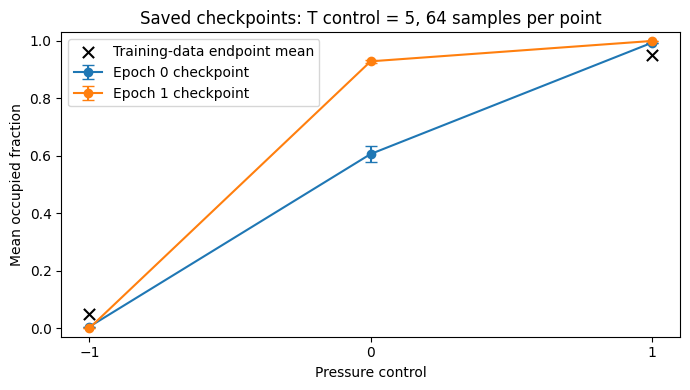

| Epoch | p control | Mean density | SEM | Data mean | Empty / Full |
|---|---:|---:|---:|---:|---|
| 0 | -1 | 0.0048828 | 0.0006738 | 0.0481045 | 16 / 0 |
| 0 | +0 | 0.6062891 | 0.0265476 | N/A | 0 / 0 |
| 0 | +1 | 0.9936719 | 0.0008277 | 0.9515275 | 0 / 11 |
| 1 | -1 | 0.0000391 | 0.0000391 | 0.0481045 | 63 / 0 |
| 1 | +0 | 0.9290234 | 0.0061423 | N/A | 0 / 0 |
| 1 | +1 | 0.9999609 | 0.0000391 | 0.9515275 | 0 / 63 |

Epoch 1 minus epoch 0 (same sampling-seed protocol):
p=-1: -0.0048437
p=+0: +0.3227344
p=+1: +0.0062891
New epoch 1 mean minus previously saved mean:
p=-1: +0.0000000000
p=+0: +0.0000000000
p=+1: +0.0000000000
A discrepancy here requires checking settings/state/source; it is not evidence of a training-seed effect.
Saved to: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\from_scratch_20261031_233453_878025\checkpoint_comparison_20261031_235836_821421


In [14]:
if comparison_results is not None:
    from IPython.display import display, Markdown
    table = ["| Epoch | p control | Mean density | SEM | Data mean | Empty / Full |",
             "|---|---:|---:|---:|---:|---|"]
    fig, ax = plt.subplots(figsize=(7, 4))
    for epoch in [0, 1]:
        rows = [r for r in comparison_results if r["epoch"] == epoch]
        ax.errorbar([r["pressure_control"] for r in rows], [r["density_mean"] for r in rows],
                    yerr=[r["density_sem"] for r in rows], marker="o", capsize=4,
                    label=f"Epoch {epoch} checkpoint")
        for r in rows:
            ref = "N/A" if r["reference_data_mean"] is None else f"{r['reference_data_mean']:.7f}"
            table.append(f"| {epoch} | {r['pressure_control']:+d} | {r['density_mean']:.7f} | "
                         f"{r['density_sem']:.7f} | {ref} | {r['empty_count']} / {r['full_count']} |")
    refs = [r for r in comparison_results if r["epoch"] == 0 and r["reference_data_mean"] is not None]
    ax.scatter([r["pressure_control"] for r in refs], [r["reference_data_mean"] for r in refs],
               color="black", marker="x", s=65, label="Training-data endpoint mean", zorder=4)
    ax.set(xlabel="Pressure control", ylabel="Mean occupied fraction", ylim=(-0.03, 1.03),
           xticks=[-1, 0, 1], title="Saved checkpoints: T control = 5, 64 samples per point")
    ax.legend()
    fig.tight_layout()
    fig.savefig(COMPARISON_DIR / "checkpoint_density_comparison.png", dpi=180)
    plt.show()
    table_text = "\n".join(table)
    display(Markdown(table_text))
    (COMPARISON_DIR / "comparison_table.md").write_text(table_text, encoding="utf-8")

    print("Epoch 1 minus epoch 0 (same sampling-seed protocol):")
    for pressure in [-1, 0, 1]:
        rows = {r["epoch"]: r for r in comparison_results if r["pressure_control"] == pressure}
        print(f"p={pressure:+d}: {rows[1]['density_mean'] - rows[0]['density_mean']:+.7f}")
    # A descriptive consistency check against the previous epoch 1 evaluation.
    previous = json.loads((EVAL_DIR / "results.json").read_text(encoding="utf-8"))
    previous_means = {r["pressure_control"]: r["density_mean"] for r in previous}
    print("New epoch 1 mean minus previously saved mean:")
    for r in comparison_results:
        if r["epoch"] == 1:
            print(f"p={r['pressure_control']:+d}: {r['density_mean'] - previous_means[r['pressure_control']]:+.10f}")
    print("A discrepancy here requires checking settings/state/source; it is not evidence of a training-seed effect.")
    print("Saved to:", COMPARISON_DIR)

## 5. Recorded matched-size and public-checkpoint experiments

The following eight original code cells now require `RUN_MATCHED_SIZE_WORKFLOW=True`.
Enabling it reruns all three subset training seeds and all associated sampling.
Retained outputs are historical records from the uploaded notebook, not executions of this revision.


In [25]:
if RUN_MATCHED_SIZE_WORKFLOW:
    from datetime import datetime
    import hashlib
    import json
    import numpy as np

    # Fixed before evaluating any new model.
    SUBSET_SEED = 20261101
    SUBSET_TRAINING_SEED = 42
    N_PER_ENDPOINT = 1000

    subset_low_path = DATA_DIR / "LowMuT7.npy"
    subset_high_path = DATA_DIR / "HighMuT7.npy"

    subset_low_all = np.load(subset_low_path, allow_pickle=False)
    subset_high_all = np.load(subset_high_path, allow_pickle=False)

    for data in (subset_low_all, subset_high_all):
        assert data.shape[1:] == (2, 20, 20)
        assert len(data) >= N_PER_ENDPOINT
        assert np.isfinite(data).all()

    # Local RNG: selecting data does not alter the training RNG.
    subset_rng = np.random.default_rng(SUBSET_SEED)
    subset_low_indices = np.sort(
        subset_rng.choice(len(subset_low_all), N_PER_ENDPOINT, replace=False)
    )
    subset_high_indices = np.sort(
        subset_rng.choice(len(subset_high_all), N_PER_ENDPOINT, replace=False)
    )

    subset_low = subset_low_all[subset_low_indices].copy()
    subset_high = subset_high_all[subset_high_indices].copy()

    SUBSET_RUN_DIR = ROOT / "outputs" / (
        "matched_size_2000_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )
    SUBSET_RUN_DIR.mkdir(parents=True, exist_ok=False)

    np.savez_compressed(
        SUBSET_RUN_DIR / "fixed_subset.npz",
        low_indices=subset_low_indices,
        high_indices=subset_high_indices,
        low_data=subset_low,
        high_data=subset_high,
    )

    subset_config = {
        "description": "Match the visible author training size; original subset unknown.",
        "subset_seed": SUBSET_SEED,
        "training_seed": SUBSET_TRAINING_SEED,
        "samples_per_endpoint": N_PER_ENDPOINT,
        "total_samples": 2000,
        "epochs": 2,
        "batch_size": 64,
        "expected_optimizer_updates": 64,
        "original_author_subset_recovered": False,
        "data_sha256": {
            path.name: hashlib.sha256(path.read_bytes()).hexdigest()
            for path in (subset_low_path, subset_high_path)
        },
    }
    (SUBSET_RUN_DIR / "config.json").write_text(
        json.dumps(subset_config, indent=2), encoding="utf-8"
    )

    for name, selected, full in [
        ("LowMuT7", subset_low, subset_low_all),
        ("HighMuT7", subset_high, subset_high_all),
    ]:
        selected_density = (selected[:, 0] >= 0).mean()
        full_density = (full[:, 0] >= 0).mean()
        print(
            f"{name}: selected={len(selected)}, "
            f"subset density={selected_density:.7f}, "
            f"full-data density={full_density:.7f}"
        )

    print("Planned training: 2 epochs, batch size 64, 64 optimizer updates.")
    print("Saved to:", SUBSET_RUN_DIR)
else:
    print("Recorded matched-size workflow skipped; see the review summary above.")


LowMuT7: selected=1000, subset density=0.0480575, full-data density=0.0481045
HighMuT7: selected=1000, subset density=0.9516400, full-data density=0.9515275
Planned training: 2 epochs, batch size 64, 64 optimizer updates.
Saved to: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\matched_size_2000_20261101_004025_753930


In [26]:
if RUN_MATCHED_SIZE_WORKFLOW:
    import random
    import time
    import torch

    # A separate model directory prevents overwriting previous checkpoints.
    SUBSET_MODEL_DIR = SUBSET_RUN_DIR / "models"
    SUBSET_MODEL_DIR.mkdir(exist_ok=False)

    # Reload the exact saved subset.
    with np.load(SUBSET_RUN_DIR / "fixed_subset.npz",
                 allow_pickle=False) as saved:
        selected_low = saved["low_data"].copy()
        selected_high = saved["high_data"].copy()

    # Preserve the author's order: low endpoint, then high endpoint.
    subset_coordinates = np.concatenate(
        [selected_low[:, 0], selected_high[:, 0]], axis=0
    )
    subset_pressures = np.concatenate([
        -np.ones(len(selected_low)),
        np.ones(len(selected_high)),
    ])
    subset_temperatures = np.full(len(subset_coordinates), 5.0)

    subset_training_data = np.empty(
        (len(subset_coordinates), 3, 20, 20), dtype=np.float64
    )
    subset_training_data[:, 0] = subset_coordinates
    subset_training_data[:, 1] = 5.0
    subset_training_data[:, 2] = subset_pressures[:, None, None]

    assert subset_training_data.shape == (2000, 3, 20, 20)

    # Reset before both Loader preprocessing and network initialization.
    random.seed(SUBSET_TRAINING_SEED)
    np.random.seed(SUBSET_TRAINING_SEED)
    torch.manual_seed(SUBSET_TRAINING_SEED)
    torch.set_num_threads(2)

    subset_loader = Loader(
        data=subset_training_data,
        pressures=subset_pressures[:, None],
        temperatures=subset_temperatures[:, None],
        control_dims=(1, 3),
    )
    assert torch.isfinite(subset_loader.data).all()

    subset_prior = GlobalEquilibriumHarmonicPrior(
        shape=subset_loader.data.shape,
        channels_info={
            "coordinate": [0],
            "fluctuation": [1],
            "mean": [2],
        },
    )
    subset_model = Unet2D(
        dim=32,
        dim_mults=(1, 2, 4),
        resnet_block_groups=8,
        channels=3,
    )
    subset_backbone = ConvBackbone(
        model=subset_model,
        data_shape=subset_loader.data_dim,
        target_shape=32,
        num_dims=4,
        lr=1e-3,
        eval_mode="train",
        self_condition=True,
    )
    subset_diffusion = VPDiffusion(num_diffusion_timesteps=100)

    # Fresh initialization: no checkpoint is loaded.
    assert subset_backbone.start_epoch == 0
    assert len(subset_backbone.optim.state_dict()["state"]) == 0

    torch.save(
        torch.get_rng_state(),
        SUBSET_RUN_DIR / "before_training_rng.pt",
    )

    subset_trainer = DiffusionTrainer(
        subset_diffusion,
        subset_backbone,
        subset_loader,
        subset_prior,
        model_dir=str(SUBSET_MODEL_DIR),
        pred_type="noise",
    )

    print("Training from scratch: 2000 samples, 2 epochs, batch size 64.")
    print("Output directory:", SUBSET_RUN_DIR)
    subset_started = time.monotonic()

    subset_trainer.train(
        2,
        loss_type="smooth_l1",
        batch_size=64,
    )

    subset_steps = sorted({
        float(state["step"])
        for state in subset_backbone.optim.state_dict()["state"].values()
        if "step" in state
    })
    assert subset_steps == [64.0], subset_steps

    subset_checkpoints = [
        SUBSET_MODEL_DIR / f"model_{epoch}.pt"
        for epoch in [0, 1]
    ]
    assert all(path.is_file() for path in subset_checkpoints)

    subset_summary = {
        "train_losses": [float(x) for x in subset_trainer.train_losses],
        "optimizer_steps": subset_steps,
        "elapsed_seconds": time.monotonic() - subset_started,
        "checkpoints": [str(path) for path in subset_checkpoints],
        "checkpoint_sha256": {
            path.name: hashlib.sha256(path.read_bytes()).hexdigest()
            for path in subset_checkpoints
        },
        "torch_version": str(torch.__version__),
    }
    (SUBSET_RUN_DIR / "training_summary.json").write_text(
        json.dumps(subset_summary, indent=2), encoding="utf-8"
    )
    torch.save(
        torch.get_rng_state(),
        SUBSET_RUN_DIR / "after_training_rng.pt",
    )

    print(json.dumps(subset_summary, indent=2))
    print("Training finished. Density evaluation is the next step.")
else:
    print("Recorded matched-size workflow skipped; see the review summary above.")


Training from scratch: 2000 samples, 2 epochs, batch size 64.
Output directory: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\matched_size_2000_20261101_004025_753930
epoch: 0 | train loss: 0.425
epoch: 1 | train loss: 0.167
{
  "train_losses": [
    0.4254912734031677,
    0.16655121743679047
  ],
  "optimizer_steps": [
    64.0
  ],
  "elapsed_seconds": 60.687000000005355,
  "checkpoints": [
    "C:\\Users\\user\\Documents\\GitHub\\exptm_author_code_reproduction_v1\\outputs\\matched_size_2000_20261101_004025_753930\\models\\model_0.pt",
    "C:\\Users\\user\\Documents\\GitHub\\exptm_author_code_reproduction_v1\\outputs\\matched_size_2000_20261101_004025_753930\\models\\model_1.pt"
  ],
  "checkpoint_sha256": {
    "model_0.pt": "25581d59fecaca35557699f4fb7d17d055d067258953217a533687242a0a815a",
    "model_1.pt": "d2d92a2842bd622639706413e543b7e3adbcbc2d8526393f230fa4f04840f6d2"
  },
  "torch_version": "2.5.1+cpu"
}
Training finished. Density evaluation is t

In [27]:
if RUN_MATCHED_SIZE_WORKFLOW:
    from datetime import datetime
    import hashlib
    import json
    import random
    import time

    # Evaluate the saved checkpoint after two training epochs.
    subset_checkpoint = SUBSET_MODEL_DIR / "model_1.pt"
    assert subset_checkpoint.is_file()

    subset_backbone.load_model(
        str(SUBSET_MODEL_DIR), 1, device="cpu"
    )

    subset_sampler = SteeredDiffusionSampler(
        subset_diffusion,
        subset_backbone,
        subset_loader,
        subset_prior,
        pred_type="noise",
    )

    SUBSET_EVAL_DIR = SUBSET_RUN_DIR / (
        "density_check_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )
    SUBSET_EVAL_DIR.mkdir(parents=True, exist_ok=False)

    sampling_seed = 2026103101
    sample_count = 64
    batch_size = 16

    evaluation_config = {
        "checkpoint": str(subset_checkpoint),
        "checkpoint_sha256": hashlib.sha256(
            subset_checkpoint.read_bytes()
        ).hexdigest(),
        "training_samples": 2000,
        "checkpoint_epoch": 1,
        "temperature_control": 5,
        "pressure_controls": [-1, 0, 1],
        "sampling_seed_per_control": sampling_seed,
        "samples_per_control": sample_count,
        "batch_size": batch_size,
        "backbone_eval_mode": "train",
        "eta": 1,
        "gamma": 1,
        "decode": "coordinate >= 0",
    }

    (SUBSET_EVAL_DIR / "config.json").write_text(
        json.dumps(evaluation_config, indent=2), encoding="utf-8"
    )

    subset_evaluation_results = []

    for p in [-1, 0, 1]:
        # Use the same sampling seed separately for each control.
        random.seed(sampling_seed)
        np.random.seed(sampling_seed)
        torch.manual_seed(sampling_seed)

        tag = f"p_{p:+d}"
        torch.save(
            torch.get_rng_state(),
            SUBSET_EVAL_DIR / f"{tag}_initial_rng.pt",
        )

        print(f"\nSampling: T=5, pressure={p:+d}", flush=True)
        started = time.monotonic()
        batches = []

        for batch_index in range(sample_count // batch_size):
            samples = subset_sampler.sample_loop(
                num_samples=batch_size,
                batch_size=batch_size,
                temperature=5,
                pressure=p,
                eta=1,
                gamma=1,
            )

            values = samples.detach().cpu().numpy()
            assert values.shape == (batch_size, 3, 20, 20)
            assert np.isfinite(values).all()
            assert np.all(values[:, 1] == 5)
            assert np.all(values[:, 2] == p)

            batches.append(values)
            print(
                f"Completed {(batch_index + 1) * batch_size}/{sample_count}",
                flush=True,
            )

        generated = np.concatenate(batches, axis=0)
        rho = (generated[:, 0] >= 0).mean(axis=(1, 2))

        full_reference = None
        subset_reference = None

        if p != 0:
            full_data = subset_low_all if p == -1 else subset_high_all
            selected_data = selected_low if p == -1 else selected_high

            full_reference = float((full_data[:, 0] >= 0).mean())
            subset_reference = float((selected_data[:, 0] >= 0).mean())

        row = {
            "pressure_control": p,
            "temperature_control": 5,
            "samples": len(rho),
            "density_mean": float(rho.mean()),
            "density_sd": float(rho.std(ddof=1)),
            "density_sem": float(rho.std(ddof=1) / np.sqrt(len(rho))),
            "full_data_reference_mean": full_reference,
            "subset_reference_mean": subset_reference,
            "difference_from_subset": (
                None if subset_reference is None
                else float(rho.mean() - subset_reference)
            ),
            "density_min": float(rho.min()),
            "density_max": float(rho.max()),
            "empty_samples": int(np.count_nonzero(rho == 0)),
            "full_samples": int(np.count_nonzero(rho == 1)),
            "elapsed_seconds": time.monotonic() - started,
        }

        np.save(SUBSET_EVAL_DIR / f"{tag}_samples.npy", generated)
        np.save(SUBSET_EVAL_DIR / f"{tag}_densities.npy", rho)
        torch.save(
            torch.get_rng_state(),
            SUBSET_EVAL_DIR / f"{tag}_final_rng.pt",
        )

        subset_evaluation_results.append(row)
        (SUBSET_EVAL_DIR / "results.json").write_text(
            json.dumps(subset_evaluation_results, indent=2),
            encoding="utf-8",
        )
        print(json.dumps(row, indent=2), flush=True)

    print("\nSummary:")
    for row in subset_evaluation_results:
        print(
            f"p={row['pressure_control']:+d} | "
            f"density={row['density_mean']:.7f} "
            f"+/- {row['density_sem']:.7f} SEM | "
            f"empty={row['empty_samples']}/64 | "
            f"full={row['full_samples']}/64"
        )

    print("\nResults saved to:", SUBSET_EVAL_DIR)
else:
    print("Recorded matched-size workflow skipped; see the review summary above.")



Sampling: T=5, pressure=-1
Completed 16/64
Completed 32/64
Completed 48/64
Completed 64/64
{
  "pressure_control": -1,
  "temperature_control": 5,
  "samples": 64,
  "density_mean": 0.2581640625,
  "density_sd": 0.024276197547414856,
  "density_sem": 0.003034524693426857,
  "full_data_reference_mean": 0.0481045,
  "subset_reference_mean": 0.0480575,
  "difference_from_subset": 0.2101065625,
  "density_min": 0.195,
  "density_max": 0.32,
  "empty_samples": 0,
  "full_samples": 0,
  "elapsed_seconds": 57.1880000000092
}

Sampling: T=5, pressure=+0
Completed 16/64
Completed 32/64
Completed 48/64
Completed 64/64
{
  "pressure_control": 0,
  "temperature_control": 5,
  "samples": 64,
  "density_mean": 0.4983984375,
  "density_sd": 0.021695800867855032,
  "density_sem": 0.002711975108481879,
  "full_data_reference_mean": null,
  "subset_reference_mean": null,
  "difference_from_subset": null,
  "density_min": 0.4475,
  "density_max": 0.5575,
  "empty_samples": 0,
  "full_samples": 0,
  "ela

In [28]:
if RUN_MATCHED_SIZE_WORKFLOW:
    from datetime import datetime
    import hashlib
    import json
    import random
    import time
    import numpy as np
    import torch

    # Reuse the exact saved subset; do not select new samples.
    fixed_subset_path = SUBSET_RUN_DIR / "fixed_subset.npz"
    assert fixed_subset_path.is_file()

    with np.load(fixed_subset_path, allow_pickle=False) as saved:
        study_low = saved["low_data"].copy()
        study_high = saved["high_data"].copy()

    assert study_low.shape == study_high.shape == (1000, 2, 20, 20)

    SEED_STUDY_DIR = SUBSET_RUN_DIR / (
        "training_seed_check_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )
    SEED_STUDY_DIR.mkdir(parents=True, exist_ok=False)

    study_config = {
        "training_seeds": [43, 44],
        "sampling_seed_per_control": 2026103101,
        "fixed_subset": str(fixed_subset_path),
        "fixed_subset_sha256": hashlib.sha256(
            fixed_subset_path.read_bytes()
        ).hexdigest(),
        "training_samples": 2000,
        "epochs": 2,
        "training_batch_size": 64,
        "expected_optimizer_updates": 64,
        "temperature_control": 5,
        "pressure_controls": [-1, 0, 1],
        "samples_per_control": 64,
        "sampling_batch_size": 16,
        "eta": 1,
        "gamma": 1,
        "backbone_eval_mode": "train",
        "decode": "coordinate >= 0",
        "seed_applied_before_loader_and_model": True,
        "torch_version": str(torch.__version__),
    }

    (SEED_STUDY_DIR / "config.json").write_text(
        json.dumps(study_config, indent=2), encoding="utf-8"
    )


    def run_training_seed(seed):
        run_dir = SEED_STUDY_DIR / f"seed_{seed}"
        model_dir = run_dir / "models"
        model_dir.mkdir(parents=True, exist_ok=False)

        # Match the seed-42 construction order, including Loader randomness.
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.set_num_threads(2)

        pressure = np.repeat([-1.0, 1.0], 1000)
        temperature = np.full(2000, 5.0)
        data = np.empty((2000, 3, 20, 20), dtype=np.float64)
        data[:, 0] = np.concatenate(
            [study_low[:, 0], study_high[:, 0]], axis=0
        )
        data[:, 1] = 5
        data[:, 2] = pressure[:, None, None]

        loader = Loader(
            data=data,
            pressures=pressure[:, None],
            temperatures=temperature[:, None],
            control_dims=(1, 3),
        )
        assert torch.isfinite(loader.data).all()

        prior = GlobalEquilibriumHarmonicPrior(
            shape=loader.data.shape,
            channels_info={
                "coordinate": [0], "fluctuation": [1], "mean": [2]
            },
        )
        model = Unet2D(
            dim=32, dim_mults=(1, 2, 4),
            resnet_block_groups=8, channels=3,
        )
        backbone = ConvBackbone(
            model=model,
            data_shape=loader.data_dim,
            target_shape=32,
            num_dims=4,
            lr=1e-3,
            eval_mode="train",
            self_condition=True,
        )
        diffusion = VPDiffusion(num_diffusion_timesteps=100)

        assert backbone.start_epoch == 0
        assert not backbone.optim.state_dict()["state"]

        torch.save(torch.get_rng_state(), run_dir / "before_training_rng.pt")

        trainer = DiffusionTrainer(
            diffusion, backbone, loader, prior,
            model_dir=str(model_dir),
            pred_type="noise",
        )

        print(f"\nTraining seed {seed}: 2 epochs", flush=True)
        started = time.monotonic()
        trainer.train(2, loss_type="smooth_l1", batch_size=64)

        steps = sorted({
            float(state["step"])
            for state in backbone.optim.state_dict()["state"].values()
            if "step" in state
        })
        assert steps == [64.0], steps

        checkpoint = model_dir / "model_1.pt"
        assert checkpoint.is_file()

        training_summary = {
            "training_seed": seed,
            "train_losses": [float(x) for x in trainer.train_losses],
            "optimizer_steps": steps,
            "training_seconds": time.monotonic() - started,
            "checkpoint": str(checkpoint),
            "checkpoint_sha256": hashlib.sha256(
                checkpoint.read_bytes()
            ).hexdigest(),
        }
        (run_dir / "training_summary.json").write_text(
            json.dumps(training_summary, indent=2), encoding="utf-8"
        )
        torch.save(torch.get_rng_state(), run_dir / "after_training_rng.pt")

        # Evaluate the saved final checkpoint without further training.
        backbone.load_model(str(model_dir), 1, device="cpu")
        sampler = SteeredDiffusionSampler(
            diffusion, backbone, loader, prior, pred_type="noise"
        )
        rows = []

        for p in [-1, 0, 1]:
            random.seed(2026103101)
            np.random.seed(2026103101)
            torch.manual_seed(2026103101)

            tag = f"p_{p:+d}"
            torch.save(torch.get_rng_state(), run_dir / f"{tag}_initial_rng.pt")
            batches = []

            for batch_index in range(4):
                samples = sampler.sample_loop(
                    num_samples=16,
                    batch_size=16,
                    temperature=5,
                    pressure=p,
                    eta=1,
                    gamma=1,
                )
                values = samples.detach().cpu().numpy()
                assert values.shape == (16, 3, 20, 20)
                assert np.isfinite(values).all()
                assert np.all(values[:, 1] == 5)
                assert np.all(values[:, 2] == p)
                batches.append(values)

                print(
                    f"Seed {seed}, p={p:+d}: {(batch_index + 1) * 16}/64",
                    flush=True,
                )

            generated = np.concatenate(batches, axis=0)
            rho = (generated[:, 0] >= 0).mean(axis=(1, 2))
            reference = (
                None if p == 0 else float(
                    ((study_low if p == -1 else study_high)[:, 0] >= 0).mean()
                )
            )

            row = {
                "training_seed": seed,
                "pressure_control": p,
                "samples": len(rho),
                "density_mean": float(rho.mean()),
                "density_sd": float(rho.std(ddof=1)),
                "density_sem": float(rho.std(ddof=1) / np.sqrt(len(rho))),
                "subset_reference_mean": reference,
                "density_min": float(rho.min()),
                "density_max": float(rho.max()),
                "empty_samples": int(np.count_nonzero(rho == 0)),
                "full_samples": int(np.count_nonzero(rho == 1)),
            }
            rows.append(row)

            np.save(run_dir / f"{tag}_samples.npy", generated)
            np.save(run_dir / f"{tag}_densities.npy", rho)
            torch.save(torch.get_rng_state(), run_dir / f"{tag}_final_rng.pt")
            (run_dir / "results.json").write_text(
                json.dumps(rows, indent=2), encoding="utf-8"
            )

            print(
                f"Density: {row['density_mean']:.7f} "
                f"+/- {row['density_sem']:.7f} SEM",
                flush=True,
            )

        return rows


    seed_study_results = []
    for training_seed in [43, 44]:
        seed_study_results.extend(run_training_seed(training_seed))
        (SEED_STUDY_DIR / "results.json").write_text(
            json.dumps(seed_study_results, indent=2), encoding="utf-8"
        )

    print("\nFinal summary:")
    for row in seed_study_results:
        print(
            f"seed={row['training_seed']} | "
            f"p={row['pressure_control']:+d} | "
            f"density={row['density_mean']:.7f} "
            f"+/- {row['density_sem']:.7f} SEM | "
            f"empty={row['empty_samples']}/64 | "
            f"full={row['full_samples']}/64"
        )

    print("\nSaved to:", SEED_STUDY_DIR)
else:
    print("Recorded matched-size workflow skipped; see the review summary above.")



Training seed 43: 2 epochs
epoch: 0 | train loss: 0.465
epoch: 1 | train loss: 0.168
Seed 43, p=-1: 16/64
Seed 43, p=-1: 32/64
Seed 43, p=-1: 48/64
Seed 43, p=-1: 64/64
Density: 0.1442969 +/- 0.0041073 SEM
Seed 43, p=+0: 16/64
Seed 43, p=+0: 32/64
Seed 43, p=+0: 48/64
Seed 43, p=+0: 64/64
Density: 0.5162109 +/- 0.0035025 SEM
Seed 43, p=+1: 16/64
Seed 43, p=+1: 32/64
Seed 43, p=+1: 48/64
Seed 43, p=+1: 64/64
Density: 0.8551172 +/- 0.0037712 SEM

Training seed 44: 2 epochs
epoch: 0 | train loss: 0.501
epoch: 1 | train loss: 0.189
Seed 44, p=-1: 16/64
Seed 44, p=-1: 32/64
Seed 44, p=-1: 48/64
Seed 44, p=-1: 64/64
Density: 0.3535937 +/- 0.0029436 SEM
Seed 44, p=+0: 16/64
Seed 44, p=+0: 32/64
Seed 44, p=+0: 48/64
Seed 44, p=+0: 64/64
Density: 0.5302344 +/- 0.0021862 SEM
Seed 44, p=+1: 16/64
Seed 44, p=+1: 32/64
Seed 44, p=+1: 48/64
Seed 44, p=+1: 64/64
Density: 0.7050781 +/- 0.0033570 SEM

Final summary:
seed=43 | p=-1 | density=0.1442969 +/- 0.0041073 SEM | empty=0/64 | full=0/64
seed=43 

In [29]:
if RUN_MATCHED_SIZE_WORKFLOW:
    import json

    baseline_rows = json.loads(
        (SUBSET_EVAL_DIR / "results.json").read_text(encoding="utf-8")
    )
    additional_rows = json.loads(
        (SEED_STUDY_DIR / "results.json").read_text(encoding="utf-8")
    )

    all_seed_rows = [
        dict(row, training_seed=42) for row in baseline_rows
    ] + additional_rows

    print("Training seed | p | Mean density | Sampling SEM | Empty / Full")
    for row in sorted(
        all_seed_rows,
        key=lambda r: (r["training_seed"], r["pressure_control"]),
    ):
        print(
            f"{row['training_seed']:13d} | "
            f"{row['pressure_control']:+d} | "
            f"{row['density_mean']:.7f} | "
            f"{row['density_sem']:.7f} | "
            f"{row['empty_samples']} / {row['full_samples']}"
        )
else:
    print("Recorded matched-size workflow skipped; see the review summary above.")


Training seed | p | Mean density | Sampling SEM | Empty / Full
           42 | -1 | 0.2581641 | 0.0030345 | 0 / 0
           42 | +0 | 0.4983984 | 0.0027120 | 0 / 0
           42 | +1 | 0.7876953 | 0.0034410 | 0 / 0
           43 | -1 | 0.1442969 | 0.0041073 | 0 / 0
           43 | +0 | 0.5162109 | 0.0035025 | 0 / 0
           43 | +1 | 0.8551172 | 0.0037712 | 0 / 0
           44 | -1 | 0.3535937 | 0.0029436 | 0 / 0
           44 | +0 | 0.5302344 | 0.0021862 | 0 / 0
           44 | +1 | 0.7050781 | 0.0033570 | 0 / 0


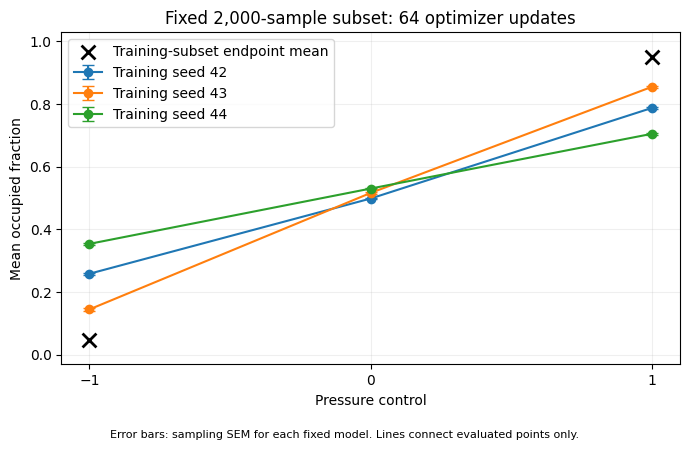

Saved to: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\matched_size_2000_20261101_004025_753930\training_seed_check_20261101_005301_969905\three_training_seeds.png


In [30]:
if RUN_MATCHED_SIZE_WORKFLOW:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7, 4.5))

    for seed in [42, 43, 44]:
        rows = sorted(
            [r for r in all_seed_rows if r["training_seed"] == seed],
            key=lambda r: r["pressure_control"],
        )
        assert len(rows) == 3

        ax.errorbar(
            [r["pressure_control"] for r in rows],
            [r["density_mean"] for r in rows],
            yerr=[r["density_sem"] for r in rows],
            marker="o",
            capsize=4,
            label=f"Training seed {seed}",
        )

    endpoint_rows = sorted(
        [r for r in baseline_rows if r["pressure_control"] != 0],
        key=lambda r: r["pressure_control"],
    )
    ax.scatter(
        [r["pressure_control"] for r in endpoint_rows],
        [r["subset_reference_mean"] for r in endpoint_rows],
        marker="x", s=100, linewidths=2, color="black",
        label="Training-subset endpoint mean",
        zorder=5,
    )

    ax.set(
        xlabel="Pressure control",
        ylabel="Mean occupied fraction",
        title="Fixed 2,000-sample subset: 64 optimizer updates",
        xticks=[-1, 0, 1],
        ylim=(-0.03, 1.03),
    )
    ax.grid(alpha=0.2)
    ax.legend()
    fig.text(
        0.5, 0.015,
        "Error bars: sampling SEM for each fixed model. "
        "Lines connect evaluated points only.",
        ha="center", fontsize=8,
    )
    fig.tight_layout(rect=(0, 0.05, 1, 1))

    figure_path = SEED_STUDY_DIR / "three_training_seeds.png"
    fig.savefig(figure_path, dpi=180)
    plt.show()
    print("Saved to:", figure_path)
else:
    print("Recorded matched-size workflow skipped; see the review summary above.")


Public checkpoint, p=-1: 16/64
Public checkpoint, p=-1: 32/64
Public checkpoint, p=-1: 48/64
Public checkpoint, p=-1: 64/64
Public checkpoint, p=+0: 16/64
Public checkpoint, p=+0: 32/64
Public checkpoint, p=+0: 48/64
Public checkpoint, p=+0: 64/64
Public checkpoint, p=+1: 16/64
Public checkpoint, p=+1: 32/64
Public checkpoint, p=+1: 48/64
Public checkpoint, p=+1: 64/64


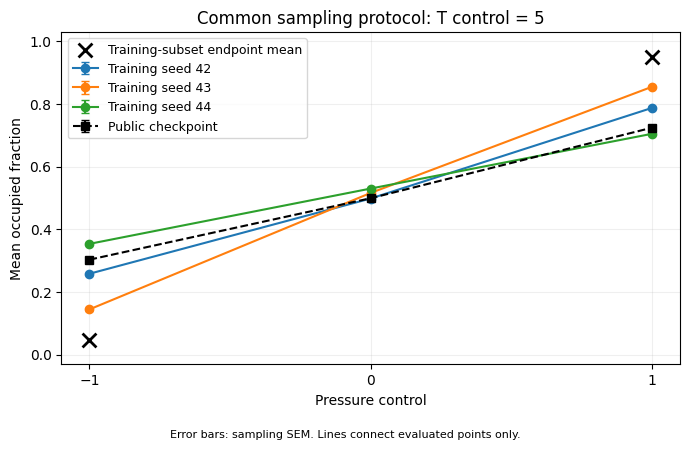


Public checkpoint summary:
p=-1 | density=0.3031250 +/- 0.0034821 SEM
p=+0 | density=0.4993359 +/- 0.0018053 SEM
p=+1 | density=0.7245313 +/- 0.0036659 SEM
Saved to: C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1\outputs\matched_size_2000_20261101_004025_753930\training_seed_check_20261101_005301_969905\public_checkpoint_20261101_010921_481162


In [31]:
if RUN_MATCHED_SIZE_WORKFLOW:
    from datetime import datetime
    import hashlib
    import json
    import random
    import numpy as np
    import torch
    import matplotlib.pyplot as plt

    # Verify that this is the previously inspected public checkpoint.
    public_model_dir = SOURCE_DIR / "thermomaps-root" / "models"
    public_checkpoint = public_model_dir / "model_1.pt"
    assert public_checkpoint.is_file()

    public_hash = hashlib.sha256(public_checkpoint.read_bytes()).hexdigest()
    expected_hash = (
        "72125a26b5d136b8eeda782ff01fbecb99963"
        "b3ad58b8fce3f4494185f5419fc"
    )
    assert public_hash == expected_hash, (
        "Public checkpoint hash mismatch. Stop and inspect the file."
    )

    # Create a separate model; retain all trained reproduction models.
    public_model = Unet2D(
        dim=32, dim_mults=(1, 2, 4),
        resnet_block_groups=8, channels=3,
    )
    public_backbone = ConvBackbone(
        model=public_model,
        data_shape=subset_loader.data_dim,
        target_shape=32,
        num_dims=4,
        lr=1e-3,
        eval_mode="train",
        self_condition=True,
    )
    public_backbone.load_model(str(public_model_dir), 1, device="cpu")

    public_sampler = SteeredDiffusionSampler(
        VPDiffusion(num_diffusion_timesteps=100),
        public_backbone,
        subset_loader,
        subset_prior,
        pred_type="noise",
    )

    PUBLIC_EVAL_DIR = SEED_STUDY_DIR / (
        "public_checkpoint_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )
    PUBLIC_EVAL_DIR.mkdir(parents=True, exist_ok=False)

    public_config = {
        "checkpoint": str(public_checkpoint),
        "checkpoint_sha256": public_hash,
        "loader": "Shared with the seed-42 subset evaluation",
        "original_checkpoint_preprocessing_recovered": False,
        "temperature_control": 5,
        "pressure_controls": [-1, 0, 1],
        "sampling_seed_per_control": 2026103101,
        "samples_per_control": 64,
        "batch_size": 16,
        "backbone_eval_mode": "train",
        "eta": 1,
        "gamma": 1,
        "decode": "coordinate >= 0",
    }
    (PUBLIC_EVAL_DIR / "config.json").write_text(
        json.dumps(public_config, indent=2), encoding="utf-8"
    )

    public_rows = []

    for p in [-1, 0, 1]:
        random.seed(2026103101)
        np.random.seed(2026103101)
        torch.manual_seed(2026103101)
        batches = []

        for batch_index in range(4):
            samples = public_sampler.sample_loop(
                num_samples=16, batch_size=16,
                temperature=5, pressure=p, eta=1, gamma=1,
            )
            values = samples.detach().cpu().numpy()
            assert values.shape == (16, 3, 20, 20)
            assert np.isfinite(values).all()
            assert np.all(values[:, 1] == 5)
            assert np.all(values[:, 2] == p)
            batches.append(values)
            print(
                f"Public checkpoint, p={p:+d}: {(batch_index + 1) * 16}/64",
                flush=True,
            )

        generated = np.concatenate(batches, axis=0)
        rho = (generated[:, 0] >= 0).mean(axis=(1, 2))
        row = {
            "pressure_control": p,
            "samples": len(rho),
            "density_mean": float(rho.mean()),
            "density_sem": float(rho.std(ddof=1) / np.sqrt(len(rho))),
            "empty_samples": int(np.count_nonzero(rho == 0)),
            "full_samples": int(np.count_nonzero(rho == 1)),
        }
        public_rows.append(row)
        np.save(PUBLIC_EVAL_DIR / f"p_{p:+d}_samples.npy", generated)
        np.save(PUBLIC_EVAL_DIR / f"p_{p:+d}_densities.npy", rho)
        (PUBLIC_EVAL_DIR / "results.json").write_text(
            json.dumps(public_rows, indent=2), encoding="utf-8"
        )

    # Compare all three reproduction seeds with the public checkpoint.
    fig, ax = plt.subplots(figsize=(7, 4.5))

    for seed in [42, 43, 44]:
        rows = sorted(
            [r for r in all_seed_rows if r["training_seed"] == seed],
            key=lambda r: r["pressure_control"],
        )
        ax.errorbar(
            [-1, 0, 1],
            [r["density_mean"] for r in rows],
            yerr=[r["density_sem"] for r in rows],
            marker="o", capsize=3, label=f"Training seed {seed}",
        )

    ax.errorbar(
        [-1, 0, 1],
        [r["density_mean"] for r in public_rows],
        yerr=[r["density_sem"] for r in public_rows],
        color="black", marker="s", linestyle="--", capsize=3,
        label="Public checkpoint",
    )
    ax.scatter(
        [r["pressure_control"] for r in endpoint_rows],
        [r["subset_reference_mean"] for r in endpoint_rows],
        color="black", marker="x", s=100, linewidths=2,
        label="Training-subset endpoint mean", zorder=5,
    )
    ax.set(
        xlabel="Pressure control",
        ylabel="Mean occupied fraction",
        title="Common sampling protocol: T control = 5",
        xticks=[-1, 0, 1], ylim=(-0.03, 1.03),
    )
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
    fig.text(
        0.5, 0.015,
        "Error bars: sampling SEM. Lines connect evaluated points only.",
        ha="center", fontsize=8,
    )
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(PUBLIC_EVAL_DIR / "public_vs_reproduction.png", dpi=180)
    plt.show()

    print("\nPublic checkpoint summary:")
    for row in public_rows:
        print(
            f"p={row['pressure_control']:+d} | "
            f"density={row['density_mean']:.7f} "
            f"+/- {row['density_sem']:.7f} SEM"
        )
    print("Saved to:", PUBLIC_EVAL_DIR)
else:
    print("Recorded matched-size workflow skipped; see the review summary above.")


In [32]:
if RUN_MATCHED_SIZE_WORKFLOW:
    # Diagnostic only: public checkpoint at temperature control 1.
    # Reuse the public sampler from the preceding comparison.
    # No training or checkpoint changes are performed.

    from datetime import datetime
    import json
    import random
    import numpy as np
    import torch

    assert "public_sampler" in globals(), "Run the public checkpoint cell first."

    TEMP_CHECK_DIR = PUBLIC_EVAL_DIR / (
        "temperature_control_1_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )
    TEMP_CHECK_DIR.mkdir(parents=True, exist_ok=False)

    config = {
        "purpose": "Temperature-control sensitivity diagnostic",
        "physical_temperature_mapping_verified": False,
        "baseline_results_directory": str(PUBLIC_EVAL_DIR),
        "temperature_control": 1,
        "pressure_controls": [-1, 0, 1],
        "sampling_seed": 2026103101,
        "samples_per_control": 64,
        "batch_size": 16,
        "eta": 1,
        "gamma": 1,
        "decoding": "coordinate channel >= 0",
    }
    (TEMP_CHECK_DIR / "config.json").write_text(
        json.dumps(config, indent=2), encoding="utf-8"
    )

    temp_check_rows = []
    python_state = random.getstate()
    numpy_state = np.random.get_state()

    try:
        with torch.random.fork_rng(devices=[]):
            for p in [-1, 0, 1]:
                random.seed(config["sampling_seed"])
                np.random.seed(config["sampling_seed"])
                torch.manual_seed(config["sampling_seed"])

                batches = []
                for batch_index in range(4):
                    with torch.no_grad():
                        batch = public_sampler.sample_loop(
                            num_samples=16,
                            batch_size=16,
                            temperature=1,
                            pressure=p,
                            eta=1,
                            gamma=1,
                        )
                    batches.append(batch.detach().cpu().numpy())
                    print(f"T control=1, p={p:+d}: {(batch_index + 1)*16}/64")

                samples = np.concatenate(batches, axis=0)
                assert samples.shape[0] == 64
                assert np.isfinite(samples).all()

                rho = (samples[:, 0] >= 0).mean(axis=(1, 2))
                row = {
                    "temperature_control": 1,
                    "pressure_control": p,
                    "samples": len(rho),
                    "density_mean": float(rho.mean()),
                    "density_sem": float(rho.std(ddof=1) / np.sqrt(len(rho))),
                    "empty_samples": int(np.count_nonzero(rho == 0)),
                    "full_samples": int(np.count_nonzero(rho == 1)),
                }
                temp_check_rows.append(row)

                np.save(TEMP_CHECK_DIR / f"samples_p{p:+d}.npy", samples)
                np.save(TEMP_CHECK_DIR / f"density_p{p:+d}.npy", rho)
                (TEMP_CHECK_DIR / "results.json").write_text(
                    json.dumps(temp_check_rows, indent=2), encoding="utf-8"
                )
                print(json.dumps(row, indent=2))
    finally:
        random.setstate(python_state)
        np.random.set_state(numpy_state)

    print("\nTemperature control 1 — public checkpoint")
    for row in temp_check_rows:
        print(
            f"p={row['pressure_control']:+d} | "
            f"density={row['density_mean']:.7f} "
            f"+/- {row['density_sem']:.7f} SEM"
        )
    print("Saved to:", TEMP_CHECK_DIR)
else:
    print("Recorded matched-size workflow skipped; see the review summary above.")


T control=1, p=-1: 16/64
T control=1, p=-1: 32/64
T control=1, p=-1: 48/64
T control=1, p=-1: 64/64
{
  "temperature_control": 1,
  "pressure_control": -1,
  "samples": 64,
  "density_mean": 0.248046875,
  "density_sem": 0.0033433020347829376,
  "empty_samples": 0,
  "full_samples": 0
}
T control=1, p=+0: 16/64
T control=1, p=+0: 32/64
T control=1, p=+0: 48/64
T control=1, p=+0: 64/64
{
  "temperature_control": 1,
  "pressure_control": 0,
  "samples": 64,
  "density_mean": 0.48441406249999996,
  "density_sem": 0.0018048571305903293,
  "empty_samples": 0,
  "full_samples": 0
}
T control=1, p=+1: 16/64
T control=1, p=+1: 32/64
T control=1, p=+1: 48/64
T control=1, p=+1: 64/64
{
  "temperature_control": 1,
  "pressure_control": 1,
  "samples": 64,
  "density_mean": 0.6919531250000001,
  "density_sem": 0.0027483697988697387,
  "empty_samples": 0,
  "full_samples": 0
}

Temperature control 1 — public checkpoint
p=-1 | density=0.2480469 +/- 0.0033433 SEM
p=+0 | density=0.4844141 +/- 0.001804

## 6. Read-only source and continuous-sample diagnostic

**Run only the next cell to continue this audit.** It is self-contained and reads the
existing Windows files without training, sampling or saving results. It can be run after
a kernel restart without running the preceding experiment cells.

The paths come from the uploaded execution outputs. Missing files are reported explicitly.
The diagnostics use the two endpoints with available reference data. `raw mean/std` and
quantiles describe continuous site values; `rho` is the mean per-configuration occupancy.
Distance to +/-1 measures departure from binary support, not total distributional error.
The 0.1 band only describes proximity to the existing zero threshold; it is not a new decoder.
The original decoder and all model settings remain unchanged.


In [1]:
# Read-only diagnostics. No model construction, sampling, training or file writes.
from pathlib import Path
import hashlib
import numpy as np

audit_root = Path(r"C:\Users\user\Documents\GitHub\exptm_author_code_reproduction_v1")
audit_source = audit_root / "author_source/GC_Lattice_gas/expTM_data_genenration"
audit_data = audit_root / "author_source/GC_Lattice_gas/data"
audit_subset = audit_root / "outputs/matched_size_2000_20261101_004025_753930"
audit_seed_dir = audit_subset / "training_seed_check_20261101_005301_969905"
audit_public = audit_seed_dir / "public_checkpoint_20261101_010921_481162"
audit_temp1 = audit_public / "temperature_control_1_20261101_011835_053730"
audit_full = audit_root / "outputs/from_scratch_20261031_233453_878025"

reviewed_hashes = {
    "loader": "3ca9e881b03ddbaea1bc1f0c61cdb61e4fa5a92bb347da0f944d84960b3b2e7a",
    "prior": "674a7427efc278ae007cafda823dcb2ebab1fe2070455d33f5968bc54b680abb",
    "diffusion_model": "849ecf96d9b2e476bffa65e31a56028db4ab82f2db45a89cfc4aa1c1135f6dce",
    "diffusion_process": "fb4b3c55444d736cb4db3917d663b5a5bd16c27a9a3eaba408abe1a656ae434c",
}
print("Current source fingerprints versus the reviewed core files:")
for name, expected in reviewed_hashes.items():
    path = audit_source / "tm/core" / (name + ".py")
    if not path.is_file():
        print(name, "MISSING", path)
        continue
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    print(name, "MATCH" if actual == expected else "DIFFERENT", actual)

def continuous_summary(label, path, channels, expected_t=None, expected_p=None):
    if not path.is_file():
        print("MISSING:", label, path)
        return None
    a = np.load(path, allow_pickle=False, mmap_mode="r")
    assert a.ndim == 4 and a.shape[1:] == (channels, 20, 20), (label, a.shape)
    assert np.isfinite(a).all(), label
    x = np.asarray(a[:, 0], dtype=np.float64)
    rho = (x >= 0).mean(axis=(1, 2))
    q = np.quantile(x, [0.01, 0.5, 0.99])
    if expected_t is not None:
        assert np.all(a[:, 1] == expected_t), (label, "T channel mismatch")
        assert np.all(a[:, 2] == expected_p), (label, "p channel mismatch")
    row = {
        "label": label, "samples": len(a), "density": float(rho.mean()),
        "raw_mean": float(x.mean()), "raw_std": float(x.std()),
        "q01": float(q[0]), "median": float(q[1]), "q99": float(q[2]),
        "mean_distance_to_binary_support": float(np.abs(np.abs(x) - 1).mean()),
        "fraction_abs_lt_0_1": float((np.abs(x) < 0.1).mean()),
    }
    print(
        f"{label:23s} | n={len(a):4d} | rho={row['density']:.7f} | "
        f"raw mean/std={row['raw_mean']:+.4f}/{row['raw_std']:.4f} | "
        f"q01/50/99={q[0]:+.3f}/{q[1]:+.3f}/{q[2]:+.3f} | "
        f"distance to +/-1={row['mean_distance_to_binary_support']:.4f} | "
        f"|x|<0.1={row['fraction_abs_lt_0_1']:.4f}"
    )
    if channels == 2:
        print("  Input coordinates all exactly -1/+1:", bool(np.isin(x, [-1, 1]).all()))
    return row

print("\nContinuous-coordinate diagnostics (all statistics except rho are site-pooled):")
continuous_audit_rows = []
for p, name in [(-1, "LowMuT7.npy"), (1, "HighMuT7.npy")]:
    cases = [
        (f"Input p={p:+d}", audit_data / name, 2, None),
        (f"10k seed42 p={p:+d}", audit_full / "density_check_20261031_234424_647084" / f"samples_pressure_{p}.npy", 3, 5),
        (f"2k seed42 p={p:+d}", audit_subset / "density_check_20261101_004729_143684" / f"p_{p:+d}_samples.npy", 3, 5),
        (f"2k seed43 p={p:+d}", audit_seed_dir / "seed_43" / f"p_{p:+d}_samples.npy", 3, 5),
        (f"2k seed44 p={p:+d}", audit_seed_dir / "seed_44" / f"p_{p:+d}_samples.npy", 3, 5),
        (f"Public T5 p={p:+d}", audit_public / f"p_{p:+d}_samples.npy", 3, 5),
        (f"Public T1 p={p:+d}", audit_temp1 / f"samples_p{p:+d}.npy", 3, 1),
    ]
    for label, path, channels, temp in cases:
        row = continuous_summary(label, path, channels, temp, p)
        if row is not None:
            continuous_audit_rows.append(row)
print("\nRead-only check complete. No results were generated or overwritten.")


Current source fingerprints versus the reviewed core files:
loader MATCH 3ca9e881b03ddbaea1bc1f0c61cdb61e4fa5a92bb347da0f944d84960b3b2e7a
prior MATCH 674a7427efc278ae007cafda823dcb2ebab1fe2070455d33f5968bc54b680abb
diffusion_model MATCH 849ecf96d9b2e476bffa65e31a56028db4ab82f2db45a89cfc4aa1c1135f6dce
diffusion_process MATCH fb4b3c55444d736cb4db3917d663b5a5bd16c27a9a3eaba408abe1a656ae434c

Continuous-coordinate diagnostics (all statistics except rho are site-pooled):
Input p=-1              | n=5000 | rho=0.0481045 | raw mean/std=-0.9038/0.4280 | q01/50/99=-1.000/-1.000/+1.000 | distance to +/-1=0.0000 | |x|<0.1=0.0000
  Input coordinates all exactly -1/+1: True
10k seed42 p=-1         | n=  64 | rho=0.0000391 | raw mean/std=-5.5383/1.1040 | q01/50/99=-8.379/-5.469/-3.456 | distance to +/-1=4.5387 | |x|<0.1=0.0000
2k seed42 p=-1          | n=  64 | rho=0.2581641 | raw mean/std=-9.8313/18.6102 | q01/50/99=-69.398/-8.731/+33.535 | distance to +/-1=14.1264 | |x|<0.1=0.0039
2k seed43 p=-1  

## Appendix — archived author examples (execution disabled)

These cells and their displayed outputs came from the uploaded notebook's old example section.
They are **not results from the new checkpoint comparison**. Some rely on missing variables
(`GC_density_1`, etc.) or use different sampling controls; they cannot establish reproduction.
Each source is retained under `if False` so Run All skips it. Running a skipped cell clears its old output;
the original upload remains available in the file's version history. To run an example later,
first define and record its inputs explicitly. The numerical summary above preserves the current run's findings.

In [15]:
if False:
    def round_lattice(array):
        # sample data extracted from lattice is not a binary number
        # So, we need to convert all the lattice element to 1 or -1
        #
        mean_val = array.mean()
        array = np.array(array)

        #report error if the input is not 2D or not the same length
        if array.ndim != 2:
            raise ValueError("Input must be a 2D array.")
        if len(set(len(row) for row in array)) != 1:
            raise ValueError("All rows of the array must have the same size.")

        i,j = array.shape
        result = np.zeros((i,j))
        for ii in range(i):
            for jj in range(j):
                if array[ii,jj]<0: result[ii,jj] =0
                else: result[ii,jj] = 1
        return result


In [16]:
if False:
    temp = 2
    pres_range = [-2.5,0,2.5]

In [17]:
if False:
    samples_low_chem = sampler.sample_loop(num_samples=num_samp, batch_size=16, pressure=pres_range[0]  , temperature=temp)
    samples_mid_chem = sampler.sample_loop(num_samples=num_samp, batch_size=16, pressure=pres_range[1] , temperature=temp)
    samples_high_chem = sampler.sample_loop(num_samples=num_samp, batch_size=16, pressure=pres_range[2] , temperature=temp)


In [18]:
if False:
    samples_low_chem = samples_low_chem.numpy()
    samples_mid_chem = samples_mid_chem.numpy()
    samples_high_chem = samples_high_chem.numpy()

In [19]:
if False:
    print(samples_low_chem[:,-1,:,:].mean())
    print(samples_mid_chem[:,-1,:,:].mean())
    print(samples_high_chem[:,-1,:,:].mean())

In [20]:
if False:
    lattice = samples_low_chem[0,0,:,:]
    lattice = round_lattice(lattice)

    plt.subplot(1,3,1)
    plt.imshow(lattice,vmin=0, vmax=1)
    # plt.colorbar()

    lattice = samples_mid_chem[0,0,:,:]
    lattice = round_lattice(lattice)
    plt.subplot(1,3,2)
    plt.imshow(lattice,vmin=0, vmax=1)
    # plt.colorbar()

    lattice = samples_high_chem[0,0,:,:]
    lattice = round_lattice(lattice)
    plt.subplot(1,3,3)
    plt.imshow(lattice,vmin=0, vmax=1)
    # plt.colorbar()

In [21]:
if False:
    # Define temperature and pressure ranges
    number_sample = 5
    temperature_range = np.linspace(2, 10, number_sample)
    pressure_range = np.linspace(-1, 1, number_sample)

    # Initialize 2D array to store GC densities
    GC_density_heatmap = np.zeros((len(temperature_range), len(pressure_range)))

    num_samp = 1
    # Generate GC densities for each temperature and pressure combination
    for i, temp in enumerate(temperature_range):
        for j, pres in enumerate(pressure_range):
            samples = sampler.sample_loop(num_samples=num_samp , batch_size=16, pressure=pres, temperature=temp)
            lattices = samples.cpu()[:, 0, :, :] 
        
            GC_density_avg = []
            for lattice in lattices:
                lattice = round_lattice(lattice)  # Apply round_lattice to each 2D sample
                density_i = np.sum(lattice) / np.prod(lattice.shape)
                GC_density_avg.append(density_i)
            GC_density_heatmap[i, j] = np.mean(GC_density_avg)

    # np.save('data/GC_density_heatmap.npy', GC_density_heatmap)


In [22]:
if False:
    plt.figure(figsize=(8, 6))
    plt.imshow(GC_density_heatmap, aspect='auto', origin='lower', extent=[pressure_range.min(), pressure_range.max(), temperature_range.min(), temperature_range.max()], cmap='viridis')
    plt.colorbar().set_label(label=r'Density of particle ($\rho$) ', size=15)
    plt.xlabel(r'Chemical potential ($\mu$) ')
    plt.ylabel('Temperature (T)')
    # plt.savefig('plots/GC_density_heatmap.pdf', format='pdf')



In [23]:
if False:
    plt.figure(figsize=(5,4))
    plt.plot(pres_range,GC_density,'-*')
    plt.xlabel(r'Chemical Potential ($\mu$)', fontsize=15)
    plt.ylabel(r'Density of particle ($\rho$)', fontsize=15)

In [24]:
if False:


    plt.figure(figsize=(5,4))
    plt.plot(pres_range,GC_density_1,'-*',label='T = 1')
    plt.plot(pres_range,GC_density_2_5,'-*',label='T = 2.5')
    plt.plot(pres_range,GC_density_3,'-*',label='T = 3')
    plt.plot(pres_range,GC_density_4,'-*',label='T = 4')
    # plt.plot(pres_range,GC_density_5,'-*',label='T = 5')
    plt.xlabel(r'Chemical Potential ($\mu$)', fontsize=15)
    plt.ylabel(r'Density of particle ($\rho$)', fontsize=15)
    plt.legend()